<a href="https://colab.research.google.com/github/vigneshwaranmanikandan/data-science/blob/main/Electricity_consumption_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"/content/energydata_complete.csv")

In [3]:
print(df.shape)

(19735, 29)


In [4]:
display(df.head())

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [5]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [7]:
df.describe()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [10]:
df.isnull().sum()

,0
date,0
Appliances,0
lights,0
T1,0
RH_1,0
T2,0
RH_2,0
T3,0
RH_3,0
T4,0


In [11]:
df.isnull().sum().sum()

np.int64(0)

In [12]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.select_dtypes(include=np.number).columns

Index(['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4',
       'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9',
       'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility',
       'Tdewpoint', 'rv1', 'rv2'],
      dtype='object')

In [15]:
df.select_dtypes(include='object').columns

Index(['date'], dtype='object')

In [16]:
df['date'] = pd.to_datetime(df['date'])

In [17]:
df['date'].dtype

dtype('<M8[ns]')

In [18]:
df['Appliances'].describe()

,Appliances
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000


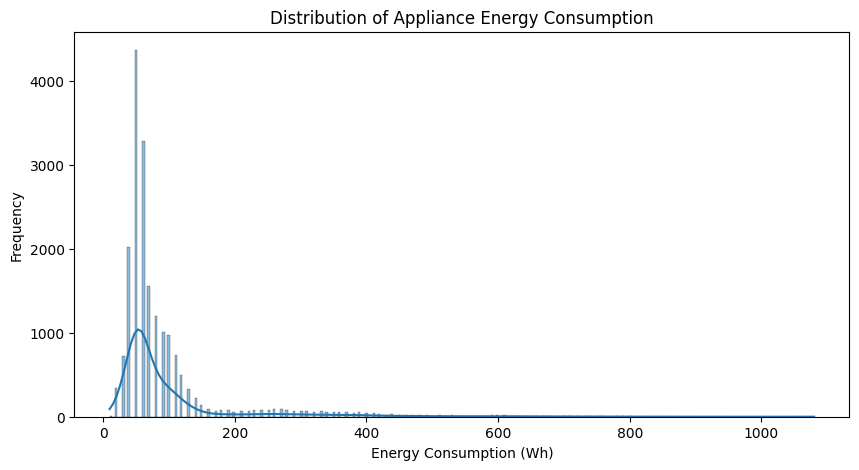

In [20]:
plt.figure(figsize=(10,5))
sns.histplot(df['Appliances'], kde=True)
plt.title('Distribution of Appliance Energy Consumption')
plt.xlabel('Energy Consumption (Wh)')
plt.ylabel('Frequency')
plt.show()

In [21]:
print("Skewness:", df['Appliances'].skew())
print("Kurtosis:", df['Appliances'].kurt())

Skewness: 3.3863672147430623
Kurtosis: 13.667863286939872


In [22]:
print("Start Date:", df['date'].min())
print("End Date:", df['date'].max())

Start Date: 2016-01-11 17:00:00
End Date: 2016-05-27 18:00:00


In [23]:
Q1 = df['Appliances'].quantile(0.25)
Q3 = df['Appliances'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower Bound: -25.0
Upper Bound: 175.0


In [24]:
outliers = df[(df['Appliances'] < lower_bound) |(df['Appliances'] > upper_bound)]
print("Number of potential outliers:", len(outliers))
print("Percentage:", len(outliers) / len(df) * 100)

Number of potential outliers: 2138
Percentage: 10.833544464149988


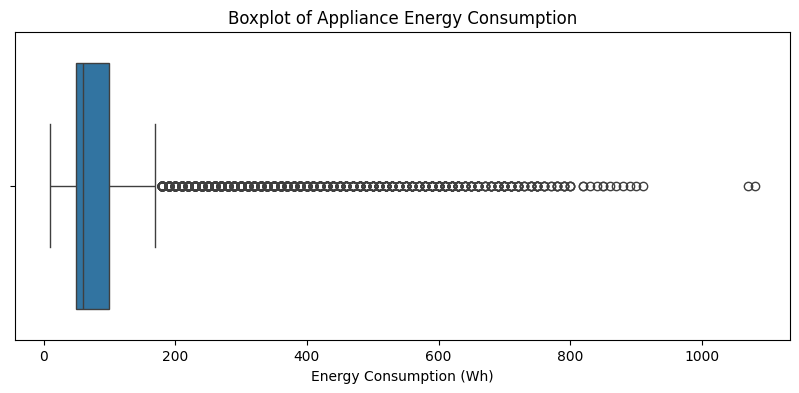

In [25]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Appliances'])
plt.title('Boxplot of Appliance Energy Consumption')
plt.xlabel('Energy Consumption (Wh)')
plt.show()

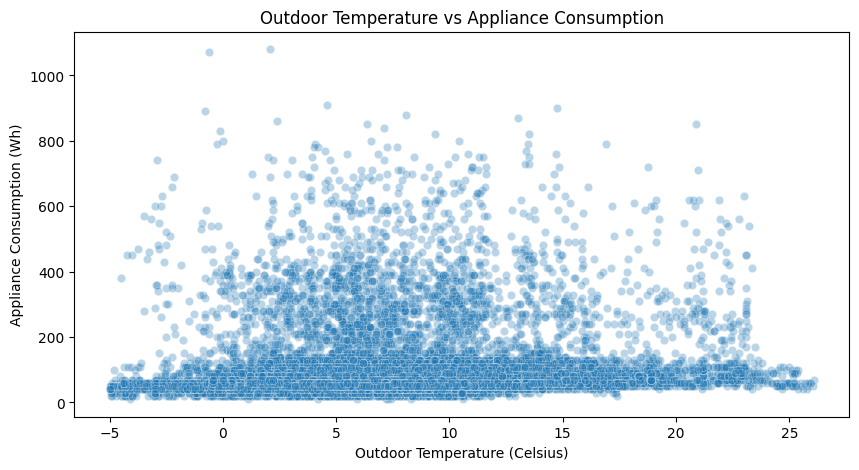

In [27]:
#Does temperature relate to electricity consumption?
#Finding is there a relationship between outdoor temperature and appliance consumption using scatter plot.
plt.figure(figsize=(10, 5))
sns.scatterplot(x=df['T_out'],y=df['Appliances'],alpha=0.3)
plt.title('Outdoor Temperature vs Appliance Consumption')
plt.xlabel('Outdoor Temperature (Celsius)')
plt.ylabel('Appliance Consumption (Wh)')
plt.show()

In [28]:
#finding pearson's correlation
correlation = df['T_out'].corr(df['Appliances'])
print("Pearson Correlation:", correlation)

Pearson Correlation: 0.09915465073995956


In [29]:
#finding correlation with all the temperature
temperature_cols = ['T1', 'T2', 'T3', 'T4','T5', 'T6', 'T7', 'T8', 'T9', 'T_out']
temp_corr = df[temperature_cols + ['Appliances']].corr()
print(temp_corr['Appliances'].sort_values(ascending=False))

Appliances    1.000000
T2            0.120073
T6            0.117638
T_out         0.099155
T3            0.085060
T1            0.055447
T4            0.040281
T8            0.039572
T7            0.025801
T5            0.019760
T9            0.010010
Name: Appliances, dtype: float64


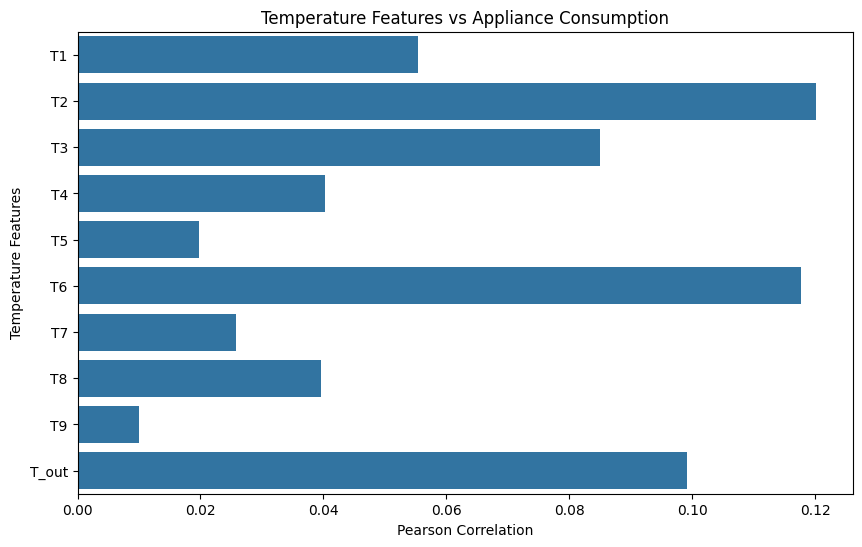

In [30]:
#visualizing correlation
plt.figure(figsize=(10, 6))
sns.barplot(x=temp_corr['Appliances'].drop('Appliances').values,y=temp_corr['Appliances'].drop('Appliances').index)
plt.title('Temperature Features vs Appliance Consumption')
plt.xlabel('Pearson Correlation')
plt.ylabel('Temperature Features')

plt.show()

In [ ]:
#Temperature variables had a weak positive  linear correlations with appliance energy consumption. T2, representing living-room temperature, had the highest correlation
#of approximately 0.12. This indicates that temperature alone has limited linear predictive power, and other environmental or behavioural factors may also contribute to
#electricity consumption.

In [31]:
#Which feature has the strongest relationship with consumption?
numeric_df = df.select_dtypes(include=np.number)
target_corr = numeric_df.corr()['Appliances']
target_corr = target_corr.drop('Appliances')
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)
print(target_corr)

lights         0.197278
RH_out        -0.152282
T2             0.120073
T6             0.117638
T_out          0.099155
RH_8          -0.094039
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
RH_6          -0.083178
RH_2          -0.060465
RH_7          -0.055642
T1             0.055447
RH_9          -0.051462
T4             0.040281
T8             0.039572
RH_3           0.036292
Press_mm_hg   -0.034885
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
rv2           -0.011145
rv1           -0.011145
T9             0.010010
RH_5           0.006955
Visibility     0.000230
Name: Appliances, dtype: float64


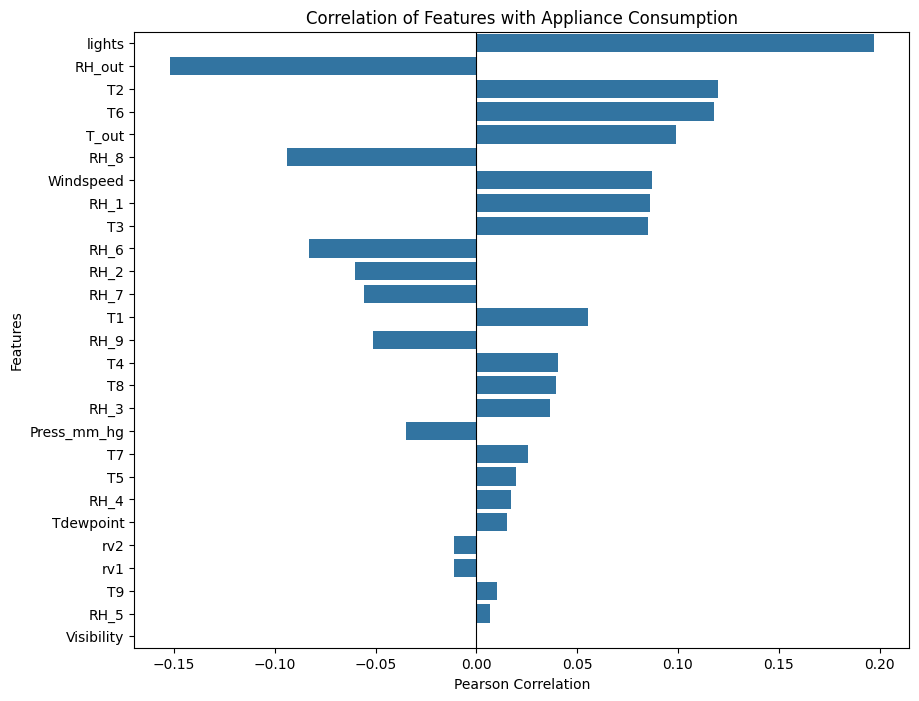

In [32]:
plt.figure(figsize=(10, 8))
sns.barplot(x=target_corr.values,y=target_corr.index)
plt.title('Correlation of Features with Appliance Consumption')
plt.xlabel('Pearson Correlation')
plt.ylabel('Features')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

In [ ]:
#Lighting consumption had the strongest positive linear correlation with appliance consumption, with a coefficient of approximately 0.197. Outdoor humidity showed
#strongest negative relationship, at approximately -0.152. Appliance consumption is influenced by multiple factors rather than a single variable.

In [33]:
#Simple Linear regression model
X = df[['lights']]
y = df['Appliances']

In [35]:
#Splitting dataset
from sklearn.model_selection import train_test_split
df_sorted = df.sort_values('date')
X = df_sorted[['lights']]
y = df_sorted[['Appliances']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [36]:
#Training
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [37]:
#Regression equation
print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)

Intercept:  [86.21667843]
Coefficients:  [[2.73705889]]


In [38]:
#making prediction
y_pred = model.predict(X_test)

In [39]:
#Evaluating model using regression metrics
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 49.16273700923478
MSE: 8357.722024801265
RMSE: 91.42057768796512
R2 Score: -0.008410710063399662


In [46]:
#comparing training and testing performance
y_train_pred = model.predict(X_train)
print("Training R2:", r2_score(y_train, y_train_pred))
print("Testing R2:", r2_score(y_test, y_pred))

Training R2: 0.04735076273306171
Testing R2: -0.008410710063399662


In [44]:
#compare  against a baseline model
baseline_pred = np.full(len(y_test),y_train.mean())
print("Baseline MAE:",mean_absolute_error(y_test, baseline_pred))
print("Baseline R2:",r2_score(y_test, baseline_pred))

Baseline MAE: 52.684938078385834
Baseline R2: -0.0003274733751543746


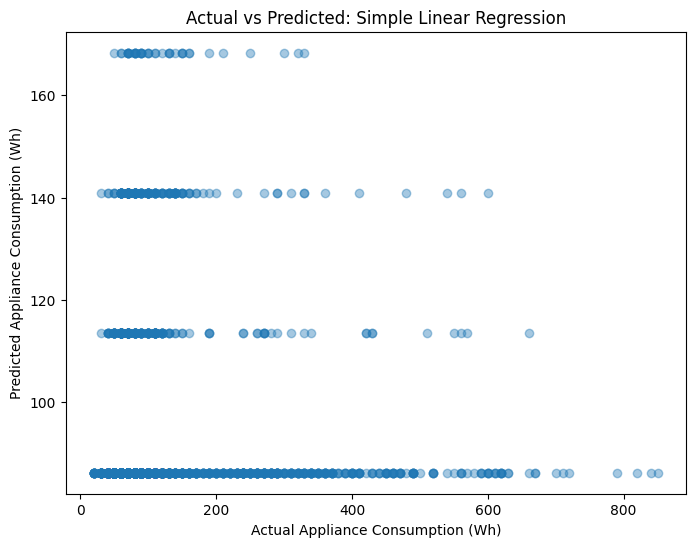

In [47]:
#actual vs predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual Appliance Consumption (Wh)")
plt.ylabel("Predicted Appliance Consumption (Wh)")
plt.title("Actual vs Predicted: Simple Linear Regression")
plt.show()

In [ ]:
#model is performing worse in test against lights

In [48]:
#moving forward to build linear regression model for T2
X = df_sorted[['T2']]
y = df_sorted['Appliances']

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,shuffle=False)

In [51]:
model_T2 = LinearRegression()
model_T2.fit(X_train, y_train)

LinearRegression()

In [53]:
print("Intercept:", model_T2.intercept_)
print("Coefficient:", model_T2.coef_)

Intercept: -114.70686842832606
Coefficient: [10.83617205]


In [54]:
y_pred_T2 = model_T2.predict(X_test)

In [57]:
mae = mean_absolute_error(y_test, y_pred_T2)
mse = mean_squared_error(y_test, y_pred_T2)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_T2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 76.07025751759963
MSE: 9590.08539579525
RMSE: 97.92898138853099
R2 Score: -0.15710295159912113


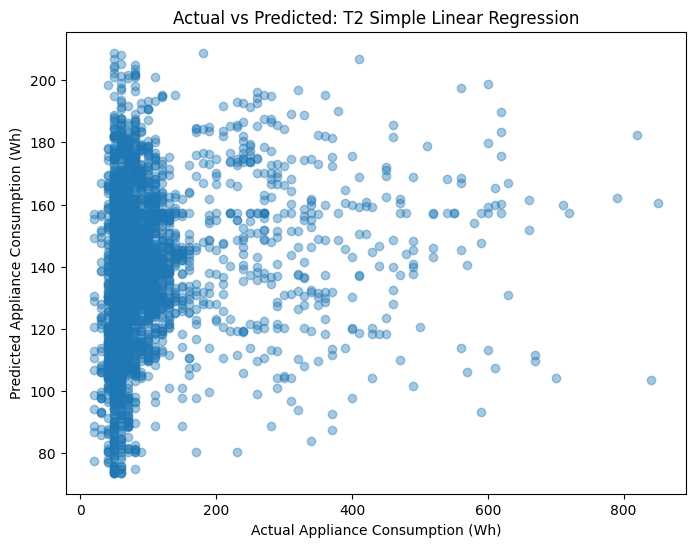

In [58]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_T2, alpha=0.4)
plt.xlabel("Actual Appliance Consumption (Wh)")
plt.ylabel("Predicted Appliance Consumption (Wh)")
plt.title("Actual vs Predicted: T2 Simple Linear Regression")
plt.show()

In [59]:
print("Training target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())
print("Training target std:", y_train.std())
print("Testing target std:", y_test.std())

Training target mean: 98.02444894856853
Testing target mean: 96.37699518621739
Training target std: 105.19829058603639
Testing target std: 91.05006480421761


In [61]:
print("Intercept:", model_T2.intercept_)
print("Coefficient:", model_T2.coef_)

Intercept: -114.70686842832606
Coefficient: [10.83617205]


In [ ]:
#Under T2, model performing even worse.

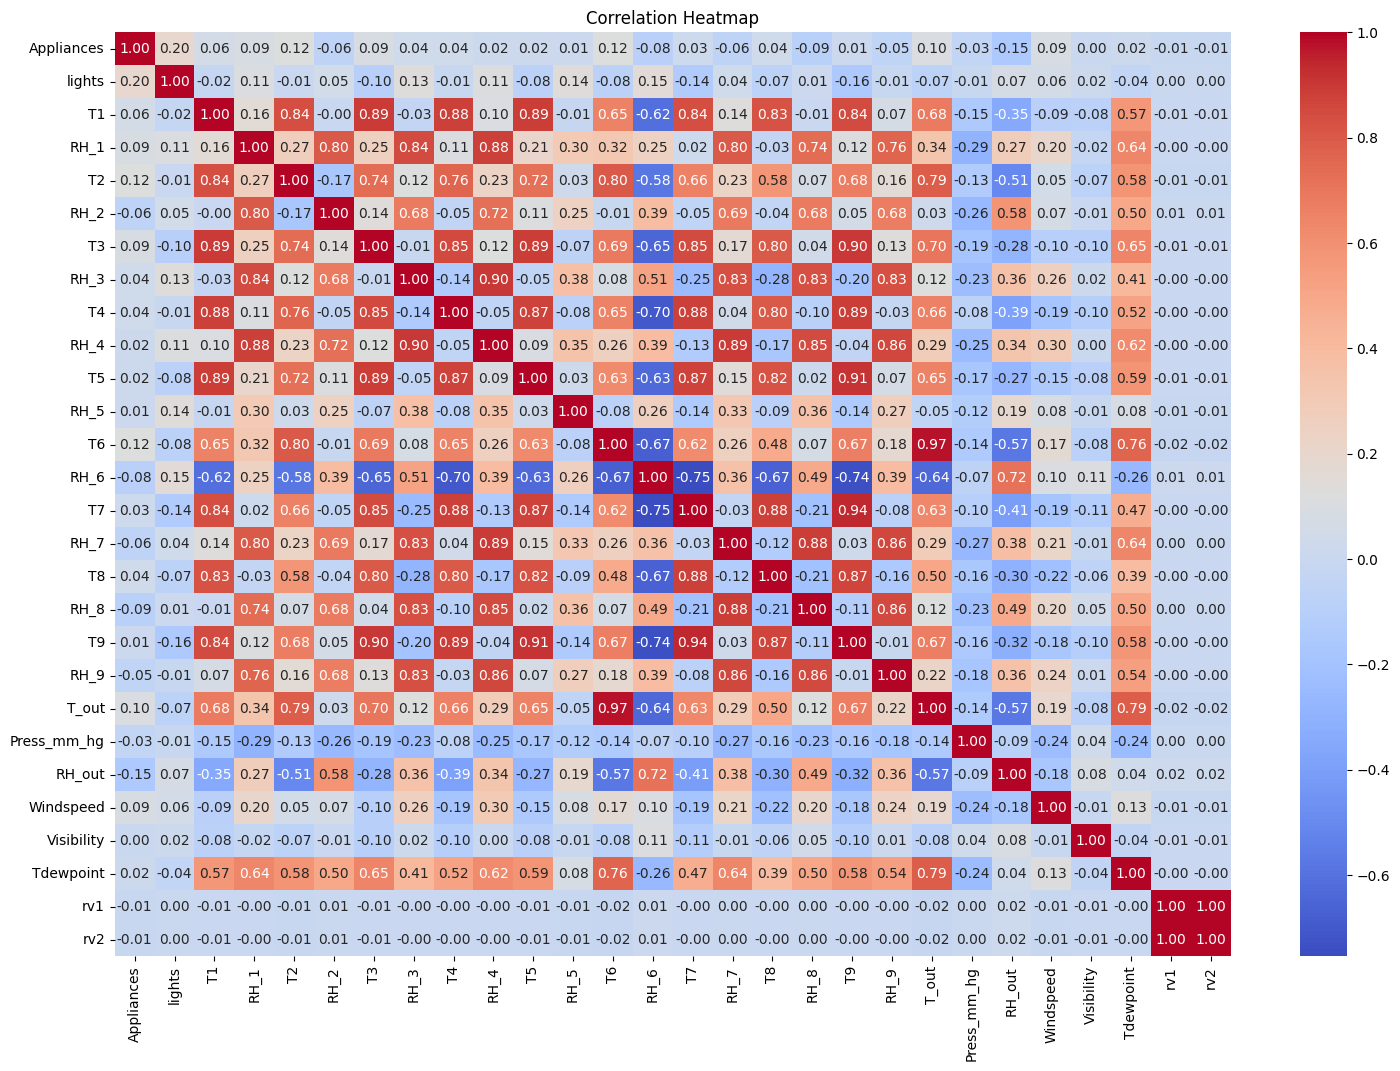

In [62]:
#Multiple linear regression model
#before building we need to find an appropriate independent variables first
#using heat map for that
plt.figure(figsize=(18, 12))
sns.heatmap(df.select_dtypes(include=np.number).corr(),cmap='coolwarm',annot=True,fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [64]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
features = ['lights','RH_out','T2','T6','T_out','RH_8','Windspeed','RH_1']
X_vif = df[features]

In [65]:
#finding vif to evaluate multicollinearity
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i)for i in range(X_vif.shape[1])]
print(vif_data.sort_values('VIF', ascending=False))

     Feature        VIF
4      T_out  23.428044
3         T6  22.241651
1     RH_out   3.345243
5       RH_8   3.159915
2         T2   3.029075
7       RH_1   2.801289
6  Windspeed   1.245927
0     lights   1.062199


In [ ]:
#T_out and T6 has higher correlation. So, initially we are excluding T_6

In [68]:
selected_features = ['lights','RH_out','T2','T_out','RH_8','Windspeed','RH_1']
X_vif_selected = df[selected_features]
vif_selected = pd.DataFrame()
vif_selected['Feature'] = selected_features
vif_selected['VIF'] = [variance_inflation_factor(X_vif_selected.values, i)for i in range(X_vif_selected.shape[1])]
print(vif_selected.sort_values('VIF', ascending=False))

     Feature       VIF
3      T_out  4.007250
1     RH_out  3.304107
4       RH_8  3.015683
2         T2  2.881746
6       RH_1  2.788683
5  Windspeed  1.245485
0     lights  1.057994


In [71]:
selected_features = ['lights','RH_out','T2','T_out','RH_8','Windspeed','RH_1']

In [72]:
#proceeding with selected features for mlr
df_sorted = df.sort_values('date').reset_index(drop=True)
X = df_sorted[selected_features]
y = df_sorted['Appliances']

In [73]:
#training and testing
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,shuffle=False)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (15788, 7)
Testing shape: (3947, 7)


In [75]:
#model building
from sklearn.linear_model import LinearRegression
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

LinearRegression()

In [76]:
#evaluating coeff
print("Intercept:", mlr_model.intercept_)
coefficients = pd.DataFrame({'Feature': selected_features,'Coefficient': mlr_model.coef_})
print(coefficients)

Intercept: -25.103915146026594
     Feature  Coefficient
0     lights     2.225535
1     RH_out    -0.642304
2         T2     4.720795
3      T_out    -1.605606
4       RH_8    -5.374943
5  Windspeed     2.314087
6       RH_1     7.571304


In [78]:
#prediction
y_pred_mlr = mlr_model.predict(X_test)

In [79]:
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
mae = mean_absolute_error(y_test, y_pred_mlr)
mse = mean_squared_error(y_test, y_pred_mlr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_mlr)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 53.547832639206234
MSE: 7806.729717170513
RMSE: 88.35569996989732
R2 Score: 0.058069910197551144


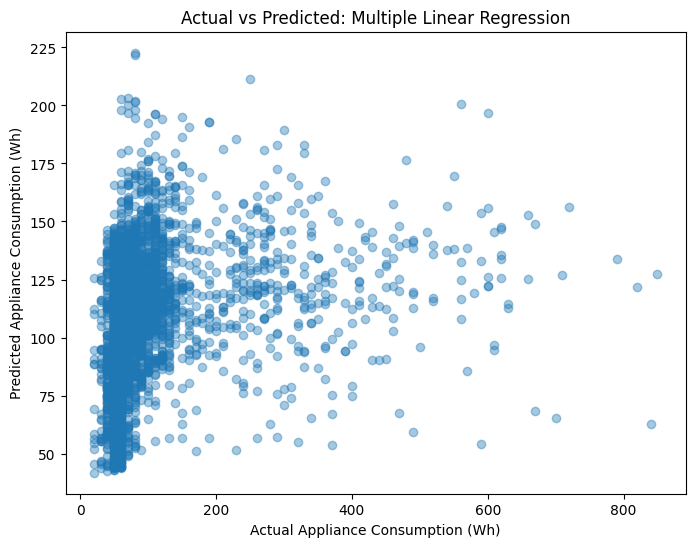

In [80]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_mlr, alpha=0.4)
plt.xlabel("Actual Appliance Consumption (Wh)")
plt.ylabel("Predicted Appliance Consumption (Wh)")
plt.title("Actual vs Predicted: Multiple Linear Regression")
plt.show()

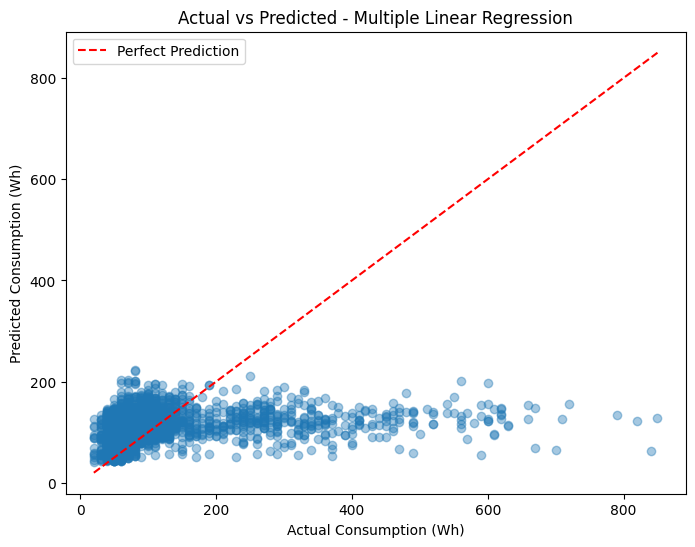

In [82]:
#evaluation
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_mlr, alpha=0.4)
min_val = min(y_test.min(), y_pred_mlr.min())
max_val = max(y_test.max(), y_pred_mlr.max())
plt.plot([min_val, max_val],[min_val, max_val],'r--',label='Perfect Prediction')
plt.xlabel('Actual Consumption (Wh)')
plt.ylabel('Predicted Consumption (Wh)')
plt.title('Actual vs Predicted - Multiple Linear Regression')
plt.legend()
plt.show()

In [84]:
print("Intercept:", mlr_model.intercept_)
coefficients = pd.DataFrame({'Feature': selected_features,'Coefficient': mlr_model.coef_})
print(coefficients.sort_values('Coefficient',ascending=False))

Intercept: -25.103915146026594
     Feature  Coefficient
6       RH_1     7.571304
2         T2     4.720795
5  Windspeed     2.314087
0     lights     2.225535
1     RH_out    -0.642304
3      T_out    -1.605606
4       RH_8    -5.374943


In [ ]:
#till now mlr model is performing good than the 2 linear regression models against lights and T2. T2 is the worst performing than others.

In [86]:
#Analyze residuals and model assumptions.
residuals = y_test - y_pred_mlr

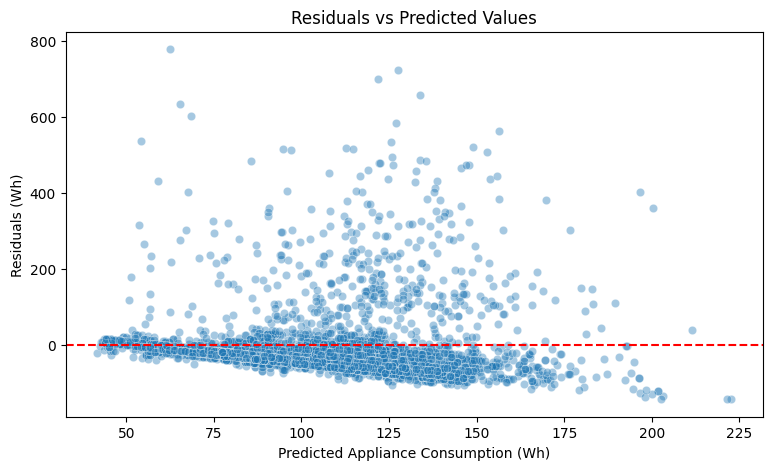

In [89]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_pred_mlr,y=residuals,alpha=0.4)
plt.axhline(y=0,color='red',linestyle='--')
plt.title('Residuals vs Predicted Values')
plt.xlabel('Predicted Appliance Consumption (Wh)')
plt.ylabel('Residuals (Wh)')
plt.show()

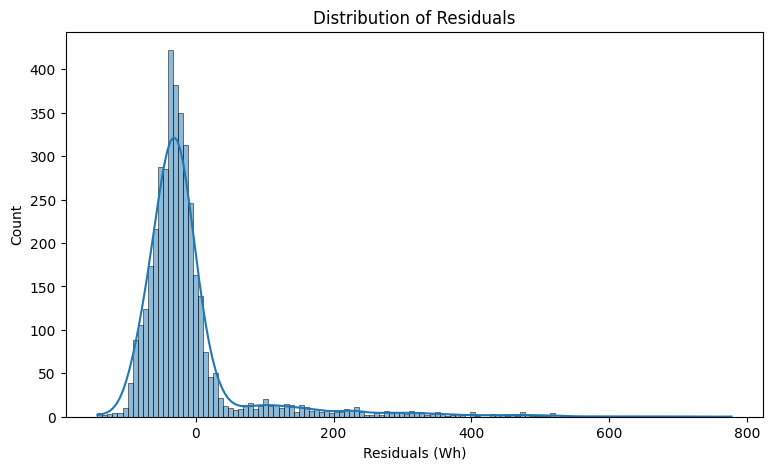

In [91]:
plt.figure(figsize=(9, 5))
sns.histplot(residuals,kde=True)
plt.title('Distribution of Residuals')
plt.xlabel('Residuals (Wh)')
plt.show()

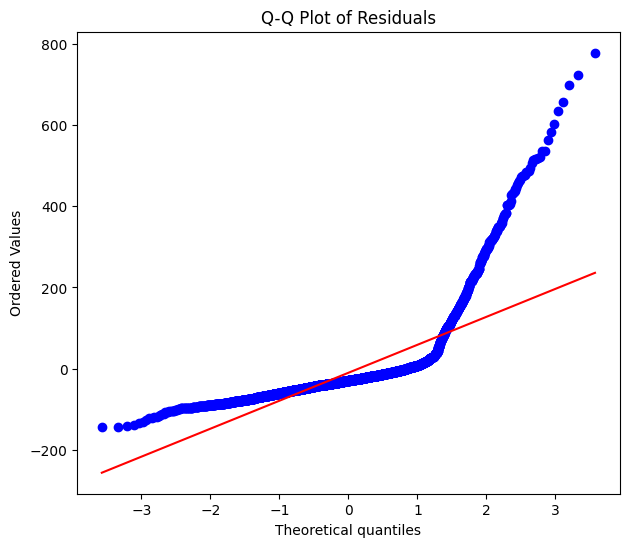

In [93]:
#using qqplot for finding the normal distribution
import scipy.stats as stats
plt.figure(figsize=(7, 6))
stats.probplot(residuals,dist='norm',plot=plt)
plt.title('Q-Q Plot of Residuals')
plt.show()

In [94]:
print("Residual Mean:", residuals.mean())
print("Residual Std:", residuals.std())
print("Residual Skewness:", residuals.skew())
print("Residual Kurtosis:", residuals.kurt())

Residual Mean: -9.762438733283393
Residual Std: 87.82584326662524
Residual Skewness: 3.6132665888838895
Residual Kurtosis: 16.564391341719396


In [95]:
#Predict electricity consumption for a household.
new_data = pd.DataFrame([X_train.median()])
display(new_data)

,lights,RH_out,T2,T_out,RH_8,Windspeed,RH_1
0,0.0,85.333333,19.566667,5.8,42.29,4.0,39.53


In [96]:
#creating new prediction
new_prediction = mlr_model.predict(new_data)
print("Predicted Appliance Consumption:",new_prediction[0],"Wh")

Predicted Appliance Consumption: 84.38754361605947 Wh


In [105]:
#calculating the prediction for random values for all the variables to check whether they fall within range
new_household = pd.DataFrame({'lights': [20],'RH_out': [80],'T2': [20],'T_out': [10],'RH_8': [45],'Windspeed': [5],'RH_1': [40]})
prediction = mlr_model.predict(new_household)
print("Predicted Consumption:", prediction[0], "Wh")

Predicted Consumption: 118.93249334450402 Wh


In [106]:
X_train.describe()

,lights,RH_out,T2,T_out,RH_8,Windspeed,RH_1
count,15788.000000,15788.000000,15788.000000,15788.000000,15788.000000,15788.000000,15788.000000
mean,4.314036,81.834642,19.631593,5.855215,42.831767,4.276856,40.037455
std,8.363499,12.920004,1.516601,4.129179,5.229067,2.555565,3.593212
min,0.000000,31.000000,16.100000,-5.000000,29.600000,0.000000,27.733333
25%,0.000000,73.333333,18.566667,2.950000,38.933333,2.000000,37.290000
50%,0.000000,85.333333,19.566667,5.800000,42.290000,4.000000,39.530000
75%,10.000000,92.000000,20.600000,8.800000,46.233333,6.000000,42.722708
max,70.000000,100.000000,24.600000,19.700000,58.780000,14.000000,63.360000
